In [ ]:
from google.colab import drive
import shutil
import zipfile
import os

# 1. Montage
drive.mount('/content/drive')

# 2. Copie et Extraction
zip_source = '/content/drive/MyDrive/archive.zip'
zip_dest = '/content/dataset.zip'

if os.path.exists(zip_source):
    shutil.copy(zip_source, zip_dest)
    with zipfile.ZipFile(zip_dest, 'r') as zip_ref:
        zip_ref.extractall('/content')
    print("✅ Archive extraite avec succès.")
else:
    print("❌ Erreur : archive.zip introuvable sur Google Drive.")

os.listdir('/content')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Archive extraite avec succès.


['.config', 'Dataset', 'dataset.zip', 'drive', 'sample_data']

In [ ]:
import os
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# 1. Configuration des chemins
BASE_PATH = "/content/drive/MyDrive/Export_GAF_1024 (1)"
IMG_SIZE = (256, 256)  # Taille cible pour le réseau

# On définit les classes et leurs dossiers correspondants
# Note : Vérifiez si vos dossiers s'appellent 'Normal', 'IRF', 'ORF' ou les noms complets
classes_mapping = {
    "Normal": "Normal",
    "IRF": "IRF",
    "ORF": "ORF"
}

def load_data(base_path, mapping):
    data = {label: [] for label in mapping.keys()}

    for label, folder_name in mapping.items():
        # Construction du chemin : /.../GAF_1024/Normal/GASF/
        # (J'ajoute GASF car c'est souvent la structure de sortie du script GAF)
        path = os.path.join(base_path, folder_name, "GASF")

        # Si le dossier GASF n'existe pas, on tente directement le dossier du label
        if not os.path.exists(path):
            path = os.path.join(base_path, folder_name)

        if not os.path.exists(path):
            print(f"⚠️ Dossier introuvable : {path}")
            continue

        # Liste des fichiers images
        files = [os.path.join(path, f) for f in os.listdir(path)
                 if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:400]

        print(f"Chargement de {label} depuis {path}...")

        for f in files:
            try:
                # Chargement en niveaux de gris (grayscale) pour un modèle Siamois classique
                img = load_img(f, target_size=IMG_SIZE, color_mode="grayscale")
                img = img_to_array(img).astype("float32") / 255.0

                # Normalisation statistique (Z-score)
                img = (img - np.mean(img)) / (np.std(img) + 1e-7)

                data[label].append(img)
            except Exception as e:
                print(f"Erreur sur {f}: {e}")

        print(f"✅ {label} : {len(data[label])} images chargées.")

    return data

# 2. Exécution du chargement
data_images = load_data(BASE_PATH, classes_mapping)

Chargement de Normal depuis /content/drive/MyDrive/Export_GAF_1024 (1)/Normal/GASF...
✅ Normal : 100 images chargées.
Chargement de IRF depuis /content/drive/MyDrive/Export_GAF_1024 (1)/IRF/GASF...
✅ IRF : 100 images chargées.
Chargement de ORF depuis /content/drive/MyDrive/Export_GAF_1024 (1)/ORF/GASF...
✅ ORF : 100 images chargées.


In [ ]:
import glob
import os

# 1. On définit le chemin racine (vérifiez bien le " (1)" à la fin)
BASE_PATH = "/content/drive/MyDrive/Export_GAF_1024 (1)"

def get_image_paths(label, method="GASF"):
    # On teste le chemin avec /GASF/
    path = os.path.join(BASE_PATH, label, method, "*.png")
    paths = sorted(glob.glob(path))

    # Si vide, on teste sans le sous-dossier method
    if not paths:
        path = os.path.join(BASE_PATH, label, "*.png")
        paths = sorted(glob.glob(path))

    return paths

# 2. Récupération des listes de chemins
paths_normal = get_image_paths("Normal")
paths_irf    = get_image_paths("IRF")
paths_orf    = get_image_paths("ORF")

# 3. Vérification immédiate
print(f"✅ Chemins récupérés :")
print(f" - Normal: {len(paths_normal)} fichiers")
print(f" - IRF: {len(paths_irf)} fichiers")
print(f" - ORF: {len(paths_orf)} fichiers")

if len(paths_normal) == 0:
    print("❌ ERREUR : Aucun fichier trouvé dans 'Normal'. Vérifiez le nom du dossier dans Drive.")

✅ Chemins récupérés :
 - Normal: 100 fichiers
 - IRF: 100 fichiers
 - ORF: 100 fichiers


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
import numpy as np

# 1. Création des paires globales (assurez-vous que paths_normal, etc. sont chargés)
def create_path_pairs(normal_paths, irf_paths, orf_paths):
    pairs = []
    labels = []
    # On utilise la première image normale comme référence saine
    ref_path = normal_paths[0]

    for p in normal_paths[1:]:
        pairs.append([ref_path, p]); labels.append(0) # 0: Normal
    for p in irf_paths:
        pairs.append([ref_path, p]); labels.append(1) # 1: IRF
    for p in orf_paths:
        pairs.append([ref_path, p]); labels.append(2) # 2: ORF
    return np.array(pairs), np.array(labels)

# Génération de X_path_pairs et y_labels
X_path_pairs, y_labels = create_path_pairs(paths_normal, paths_irf, paths_orf)

# 2. Découpage en Train (64%), Validation (16%) et Test (20%)
# Premier split : 80% (train+val) / 20% (test)
X_temp, X_test, y_temp, y_test = train_test_split(
    X_path_pairs, y_labels, test_size=0.2, stratify=y_labels, random_state=42
)

# Deuxième split : 20% de la partie temporaire pour la validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, stratify=y_temp, random_state=42
)

# 3. Calcul des poids (optionnel mais recommandé pour vos données industrielles)
weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(weights))

print(f"✅ Variables définies avec succès !")
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

✅ Variables définies avec succès !
Train: 191, Val: 48, Test: 60


In [ ]:
import tensorflow as tf

def parse_function(path1, path2, label):
    def load_and_preprocess(path):
        # Lecture du fichier
        img = tf.io.read_file(path)
        # Décodage (assurez-vous que ce sont bien des PNG)
        img = tf.image.decode_png(img, channels=1)
        # Redimensionnement (C'est ici qu'on définit la taille d'entrée du réseau)
        img = tf.image.resize(img, [256, 256])
        # Conversion en float32 et normalisation [0, 1] automatique
        img = tf.image.convert_image_dtype(img, tf.float32)
        return img

    image_a = load_and_preprocess(path1)
    image_b = load_and_preprocess(path2)

    # On retourne un tuple ((input1, input2), label) pour correspondre au modèle Siamois
    return (image_a, image_b), tf.cast(label, tf.int32)

BATCH_SIZE = 16

# --- CORRECTION : Conversion explicite en tenseurs de chaînes de caractères ---
# Cela évite les erreurs de type "String scalar expected"
train_ds = tf.data.Dataset.from_tensor_slices((
    tf.cast(X_train[:, 0], tf.string),
    tf.cast(X_train[:, 1], tf.string),
    y_train
))

# Application du pipeline
train_ds = (train_ds
            .map(parse_function, num_parallel_calls=tf.data.AUTOTUNE)
            .shuffle(buffer_size=len(X_train))
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

# Répéter pour Validation et Test
val_ds = tf.data.Dataset.from_tensor_slices((
    tf.cast(X_val[:, 0], tf.string),
    tf.cast(X_val[:, 1], tf.string),
    y_val
))
val_ds = val_ds.map(parse_function, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((
    tf.cast(X_test[:, 0], tf.string),
    tf.cast(X_test[:, 1], tf.string),
    y_test
))
test_ds = test_ds.map(parse_function, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("✅ Pipeline de données optimisé et prêt.")

✅ Pipeline de données optimisé et prêt.


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_base_network(input_shape):
    input_img = layers.Input(shape=input_shape)

    # Bloc 1 : Extraction de motifs simples
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2, 2)(x)

    # Bloc 2 : Augmentation de la profondeur
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2, 2)(x)

    # Bloc 3 : Motifs plus complexes
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2, 2)(x) # Ajout d'un pooling pour réduire la charge du GAP

    # Bloc 4 : Optionnel mais recommandé pour 256*256
    x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)

    # Transition vers le vecteur de caractéristiques
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x) # Augmenté à 256 pour plus de capacité
    x = layers.Dropout(0.4)(x)

    return models.Model(input_img, x, name="base_network")

# --- Construction du Modèle Siamois ---
input_shape = (256, 256, 1) # Images GAF en niveaux de gris
base_network = build_base_network(input_shape)

input_left = layers.Input(shape=input_shape)
input_right = layers.Input(shape=input_shape)

feat_left = base_network(input_left)
feat_right = base_network(input_right)

# Calcul de la distance absolue
distance = layers.Lambda(lambda tensors: tf.abs(tensors[0] - tensors[1]))([feat_left, feat_right])

# Tête de classification multi-classe (3 classes)
x = layers.Dense(128, activation='relu')(distance)
x = layers.Dropout(0.3)(x)
prediction = layers.Dense(3, activation='softmax')(x)

siamese_model = models.Model(inputs=[input_left, input_right], outputs=prediction)

# --- Compilation ---
siamese_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

siamese_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ base_network        │ (None, 256)       │    455,552 │ input_layer_1[0]… │
│ (Functional)        │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 256)       │          0 │ base_network[0][… │
│                     │                   │            │ base_network[1][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ lambda[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 3)         │        387 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 488,835 (1.86 MB)

 Trainable params: 487,875 (1.86 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
print("🚀 Lancement de l'entraînement pour 10 époques...")

# Configuration du callback EarlyStopping
# monitor='val_loss' : surveille l'erreur sur les données de validation
# patience=10 : si l'erreur ne diminue plus pendant 10 époques, on arrête
# restore_best_weights=True : très important, il recharge les poids de la meilleure époque
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Lancement de l'entraînement
history = siamese_model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds,
    class_weight=class_weights_dict, # Utilise les poids calculés pour équilibrer Normal/IRF/ORF
    callbacks=[early_stop]
)

🚀 Lancement de l'entraînement pour 50 époques...
Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 131s 9s/step - accuracy: 0.5393 - loss: 0.9969 - val_accuracy: 0.3125 - val_loss: 1.1172
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 135s 10s/step - accuracy: 0.6073 - loss: 0.9561 - val_accuracy: 0.3333 - val_loss: 1.1153
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 126s 9s/step - accuracy: 0.6649 - loss: 0.9066 - val_accuracy: 0.4583 - val_loss: 1.1155
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 120s 9s/step - accuracy: 0.6649 - loss: 0.8860 - val_accuracy: 0.5000 - val_loss: 1.0843
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 141s 9s/step - accuracy: 0.6963 - loss: 0.8285 - val_accuracy: 0.5417 - val_loss: 1.0602
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 141s 9s/step - accuracy: 0.7173 - loss: 0.7728 - val_accuracy: 0.6875 - val_loss: 1.0152
Epoch 7/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 145s 9s/step - accuracy: 0.8168 - loss: 0.6911 - val_accuracy: 0.5417 - val_loss: 1.0144
Epoch 8/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 118s 9s/step - accuracy

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Prédiction sur le jeu de test
# Le modèle retourne 3 probabilités par paire d'images (Softmax)
y_pred_probs = siamese_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Récupération des labels réels (y_true) depuis le test_ds
# On s'assure de parcourir tout le dataset pour extraire uniquement les étiquettes
y_true = []
for images, labels in test_ds:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

# 3. Affichage des performances
total_acc = accuracy_score(y_true, y_pred)
print(f"\n=======================================")
print(f"   ACCURACY GLOBALE : {total_acc*100:.2f} %")
print(f"=======================================\n")

# Le rapport de classification est crucial pour voir la précision par type de défaut
print("--- Rapport détaillé (Précision, Rappel, F1-Score) ---")
print(classification_report(y_true, y_pred, target_names=['Normal', 'IRF', 'ORF']))

# Petit bonus : Vérification rapide du déséquilibre
unique, counts = np.unique(y_true, return_counts=True)
print(f"\nRépartition réelle dans le test set : {dict(zip(['Normal', 'IRF', 'ORF'], counts))}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step

   ACCURACY GLOBALE : 56.67 %

--- Rapport détaillé (Précision, Rappel, F1-Score) ---
              precision    recall  f1-score   support

      Normal       0.38      0.50      0.43        20
         IRF       0.50      0.20      0.29        20
         ORF       0.77      1.00      0.87        20

    accuracy                           0.57        60
   macro avg       0.55      0.57      0.53        60
weighted avg       0.55      0.57      0.53        60


Répartition réelle dans le test set : {'Normal': np.int64(20), 'IRF': np.int64(20), 'ORF': np.int64(20)}


Résultats Globaux (Moyenne pondérée) :
Precision : 0.5513
Recall    : 0.5667
F1-Score  : 0.5300


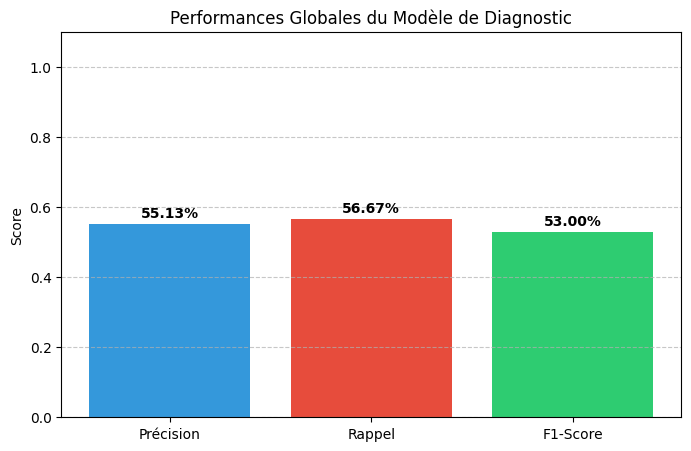


--- Détails par type de panne ---
              precision    recall  f1-score   support

      Normal       0.38      0.50      0.43        20
         IRF       0.50      0.20      0.29        20
         ORF       0.77      1.00      0.87        20

    accuracy                           0.57        60
   macro avg       0.55      0.57      0.53        60
weighted avg       0.55      0.57      0.53        60



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

# 1. Calcul des métriques globales
# 'macro' calcule la moyenne sans tenir compte du nombre d'images par classe
# 'weighted' tient compte du support (nombre d'images)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print(f"Résultats Globaux (Moyenne pondérée) :")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

# 2. Affichage graphique pour votre rapport
metrics_names = ['Précision', 'Rappel', 'F1-Score']
values = [precision, recall, f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics_names, values, color=['#3498db', '#e74c3c', '#2ecc71'])

# Ajouter les valeurs au-dessus des barres
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.2%}", ha='center', va='bottom', fontweight='bold')

plt.ylim(0, 1.1)
plt.title("Performances Globales du Modèle de Diagnostic")
plt.ylabel("Score")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 3. Rapport détaillé par classe (le plus important pour le prof)
print("\n--- Détails par type de panne ---")
print(classification_report(y_true, y_pred, target_names=['Normal', 'IRF', 'ORF']))

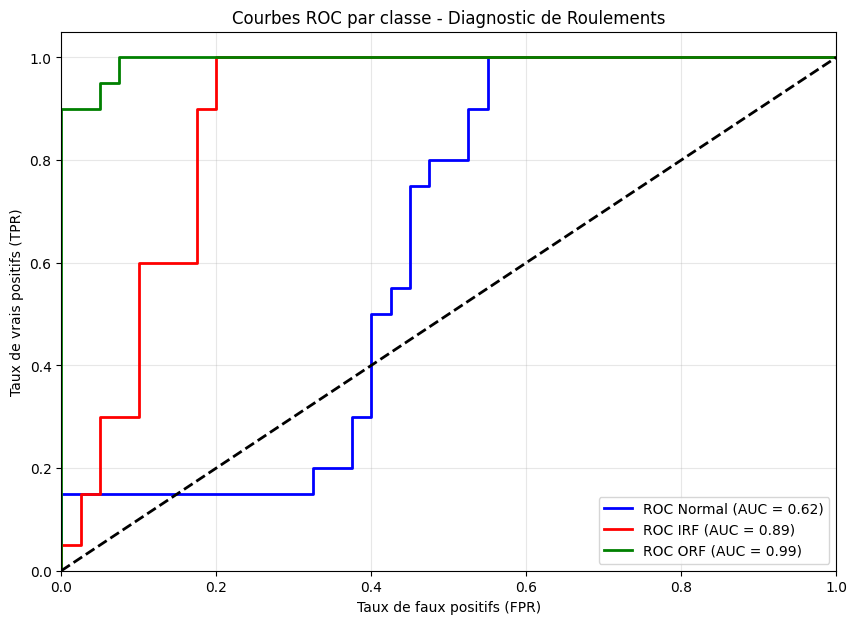

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# 1. Binarisation des labels pour le calcul multi-classe
# On transforme [0, 1, 2] en vecteurs binaires type [[1,0,0], [0,1,0], ...]
y_test_bin = label_binarize(y_true, classes=[0, 1, 2])
n_classes = 3
colors = ['blue', 'red', 'green']
target_names = ['Normal', 'IRF', 'ORF']

plt.figure(figsize=(10, 7))

# 2. Calcul et tracé de la courbe pour chaque classe
for i in range(n_classes):
    # On compare les probabilités de la classe i aux labels binaires
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, color=colors[i], lw=2,
             label=f'ROC {target_names[i]} (AUC = {roc_auc:.2f})')

# 3. Mise en forme du graphique
plt.plot([0, 1], [0, 1], 'k--', lw=2) # Ligne de chance (aléatoire)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR)')
plt.title('Courbes ROC par classe - Diagnostic de Roulements')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

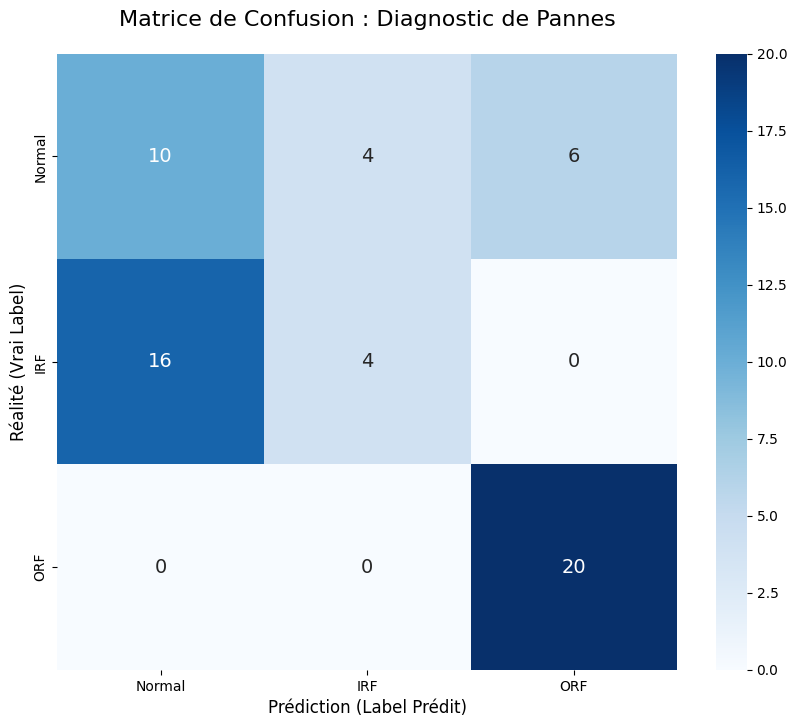

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Calcul de la matrice de confusion
cm = confusion_matrix(y_true, y_pred)

# 2. Préparation des étiquettes (noms des classes)
labels = ['Normal', 'IRF', 'ORF']

# 3. Création de la figure
plt.figure(figsize=(10, 8))

# On utilise sns.heatmap pour une visualisation élégante
# annot=True affiche les nombres
# fmt='d' empêche l'affichage en notation scientifique
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels,
            yticklabels=labels,
            annot_kws={"size": 14}) # Taille du texte dans les cases

# 4. Ajout des détails pour le rapport
plt.title('Matrice de Confusion : Diagnostic de Pannes', fontsize=16, pad=20)
plt.ylabel('Réalité (Vrai Label)', fontsize=12)
plt.xlabel('Prédiction (Label Prédit)', fontsize=12)

# Optionnel : Calcul de la précision par case en %
# cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
# sns.heatmap(cm_perc, annot=True, fmt='.2%', cmap='Blues', ...)

plt.show()

Affichage des Courbes d'Apprentissage (Loss & Accuracy) :

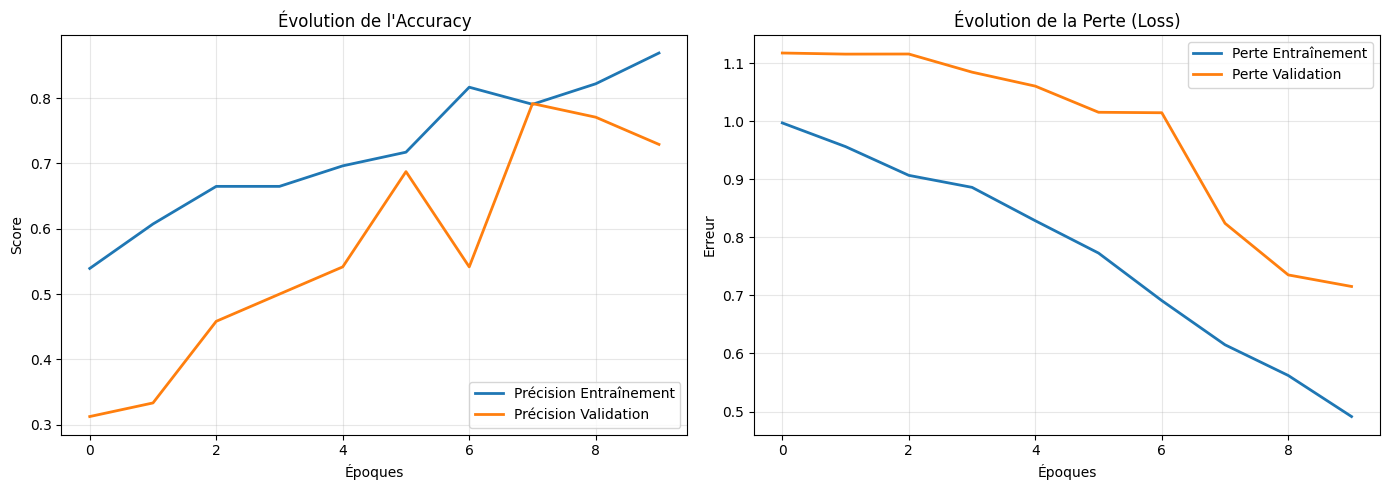

In [ ]:
import matplotlib.pyplot as plt

def plot_training_results(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Graphique de la Précision (Accuracy)
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Précision Entraînement', color='#1f77b4', lw=2)
    plt.plot(epochs_range, val_acc, label='Précision Validation', color='#ff7f0e', lw=2)
    plt.title('Évolution de l\'Accuracy')
    plt.xlabel('Époques')
    plt.ylabel('Score')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)

    # Graphique de la Perte (Loss Function)
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Perte Entraînement', color='#1f77b4', lw=2)
    plt.plot(epochs_range, val_loss, label='Perte Validation', color='#ff7f0e', lw=2)
    plt.title('Évolution de la Perte (Loss)')
    plt.xlabel('Époques')
    plt.ylabel('Erreur')
    plt.legend(loc='upper right')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_results(history)

Synthèse Globale (Matrice, Rapport et ROC):

4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step

  RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

      Normal       0.38      0.50      0.43        20
         IRF       0.50      0.20      0.29        20
         ORF       0.77      1.00      0.87        20

    accuracy                           0.57        60
   macro avg       0.55      0.57      0.53        60
weighted avg       0.55      0.57      0.53        60



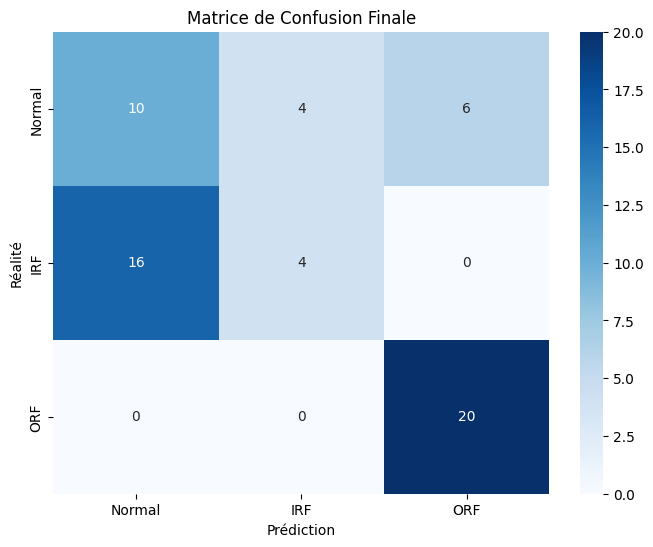

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

# 1. Calcul des prédictions
y_pred_probs = siamese_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Récupération des vrais labels
y_true = []
for _, l in test_ds:
    y_true.extend(l.numpy())
y_true = np.array(y_true)

# 3. Affichage du Rapport de Classification (Précision, Rappel, F1)
print("\n" + "="*30)
print("  RAPPORT DE CLASSIFICATION")
print("="*30)
print(classification_report(y_true, y_pred, target_names=['Normal', 'IRF', 'ORF']))

# 4. Affichage de la Matrice de Confusion
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'IRF', 'ORF'],
            yticklabels=['Normal', 'IRF', 'ORF'])
plt.title('Matrice de Confusion Finale')
plt.ylabel('Réalité')
plt.xlabel('Prédiction')
plt.show()